In [155]:
import requests
import pandas as pd
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import altair as alt
import torch
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import random
import matplotlib.gridspec as gridspec

In [3]:
# dictionary of all teams:
teams = requests.get('https://statsapi.mlb.com/api/v1/teams', params={'division' : 'Major League Baseball'}).json()

In [18]:
# hardcoded api keys:
intl_league_id = 117
pcl_league_id = 112
aaa_ids = [117, 112]

eastern_league_id = 113
southern_league_id = 111
texas_league_id = 109
aa_ids = [113, 111, 109]

midwest_league_id = 118
sally_league_id = 116 # id 148 returns a DIFFERENT south atlantic league (most recent season 1963)
northwest_league_id = 126
high_a_ids = [118, 116, 126]

carolina_league_id = 122
florida_state_league_id = 123
california_league_id = 110
low_a_ids = [122, 123, 110]

az_complex_league_id = 121
fl_complex_league_id = 123
dsl_league_id = 130
rookie_ids = [121, 123, 130]

In [115]:
def get_league_team_ids(team_dict, league_id):
    print(f'Fetching list of teams in league {league_id}:')
    print('----------------------------------------------')
    team_id_list = []
    for team in team_dict['teams']:
        if 'id' in team['league'] and team['league']['id'] == league_id:
            print(team['name'])
            team_id_list.append(team['id'])
    return team_id_list

def get_team_roster_ids(team_id):
    roster = requests.get(f'https://statsapi.mlb.com/api/v1/teams/{team_id}/roster').json()
    player_id_list = []
    #print(roster['roster'])
    for player in roster['roster']:
        print(f'{player['person']['id']}  {player['person']['fullName']}')
        player_id_list.append(player['person']['id'])
    return player_id_list

def get_team_roster_hitter_ids(team_id):
    roster = requests.get(f'https://statsapi.mlb.com/api/v1/teams/{team_id}/roster').json()
    player_id_list = []
    #print(roster['roster'])
    for player in roster['roster']:
        if player['position']['code'] != '1':
            print(f'{player['person']['id']}  {player['person']['fullName']} {player['position']}')
            player_id_list.append(player['person']['id'])
    return player_id_list

def get_minor_logs(player_id, season):
    return requests.get(f"https://statsapi.mlb.com/api/v1/people/{player_id}/stats?stats=gameLog&gameType=R&leagueListId=milb_all&group=hitting&hydrate=team(league)&language=en&season={season}",).json()

def get_major_logs(player_id, season):
    return requests.get(f'https://statsapi.mlb.com/api/v1/people/{player_id}/stats?season={season}&group=hitting&stats=gameLog',).json()

def tabulate(log_file):
    pass
    # Hardcoded dictionary of positions?
    # position_list_raw_tallies = {'P': 0, etc.}
    # position_list_percent = {'P': None, etc.} # Cuz maybe I want an undefined flag for levels that they didn't play at?
    # Do I define these for every level? Or do I wait and call them into existence when they're needed? that's probably better
    # I need to figure out how best to stack this data into a tensor. That's the key design decision here.
    # A, AA, AAA, MLB, etc = []
    #for game in log_file[]: # This is a placeholder
        # Task 1: identify level (because the minor league logs are mixed I believe)
        # This code may have to handle MLB logs different from milb because they are differently structured
        # When a level comes up, add a tally to that count, then inspect the position, and add tallies as appropriate
    # Then, outside of loop, run a function against the raw position tallies to convert them to percentages for analysis
    # Thinking further, I wanted to exclude PH (and potentially pinch runner and other such things if they're recorded) but doing so may
    # cause a divide by zero in the edgecase where that's the only appearance at that level. And I DO want to record the appearance!
    # Ultimately, this:
    # return [data package that can slide into the tensor's seasonal columns]
    # The more I think about this the more I think I want to precollate the MLB and milb logs before they enter this function, would be so much cleaner

In [16]:
def game_count_by_level(minor_logs, major_logs):
    r = 0
    low_a = 0
    hi_a = 0
    aa = 0
    aaa = 0
    if len(minor_logs['stats']) != 0:
        for game in minor_logs['stats'][0]['splits']:
            if game['league']['id'] in aaa_ids:
                aaa += 1
            elif game['league']['id'] in aa_ids:
                aa += 1
            elif game['league']['id'] in high_a_ids:
                hi_a += 1
            elif game['league']['id'] in low_a_ids:
                low_a += 1
            elif game['league']['id'] in rookie_ids:
                r += 1
    if len(major_logs['stats']) != 0:
        mlb = len(major_logs['stats'][0]['splits'])
    else:
        mlb = 0
    return [r, low_a, hi_a, aa, aaa, mlb] # Returning as list for now; may need to change structure

In [19]:
# Testing game_count_by_level using Blake Sabol's 2025. Expecting 8 MLB appearances, 66 triple A, else all zeros
sabol2025_minors = get_minor_logs(666165, 2025)
sabol2025_majors = get_major_logs(666165, 2025)
sabol2025_vector = game_count_by_level(sabol2025_minors, sabol2025_majors)
sabol2025_vector

[0, 0, 0, 0, 66, 8]

In [20]:
def get_all_season_vectors(player_id, season_start, season_stop): # start and stop are inclusive
    vector_list = []
    for season in range(season_start, season_stop + 1):
        player_minors = get_minor_logs(player_id, season)
        player_majors = get_major_logs(player_id, season)
        season_vec = game_count_by_level(player_minors, player_majors)
        vector_list.append(season_vec) # maintains each season as a separately nested vector in list
    return vector_list

In [21]:
# Testing get_all_season_vectors with Blake Sabol 2021-2026
sabol_vector_list = get_all_season_vectors(666165, 2021, 2026)
sabol_vector_list

[[0, 14, 52, 0, 0, 0],
 [0, 0, 0, 98, 25, 0],
 [0, 0, 0, 0, 0, 110],
 [0, 0, 0, 3, 97, 11],
 [0, 0, 0, 0, 66, 8],
 [0, 0, 0, 0, 101, 0]]

I confirmed via b-ref that the above vector list is accurate for Sabol's 2021-2026.

In [6]:
intl_league_team_ids = get_league_team_ids(teams, intl_league_id)
print(intl_league_team_ids)

Fetching list of teams in league 117:
----------------------------------------------
Durham Bulls
Memphis Redbirds
Louisville Bats
Buffalo Bisons
Gwinnett Stripers
Columbus Clippers
Iowa Cubs
Indianapolis Indians
Charlotte Knights
Toledo Mud Hens
Scranton/Wilkes-Barre RailRiders
Worcester Red Sox
Rochester Red Wings
Omaha Storm Chasers
Syracuse Mets
Nashville Sounds
Jacksonville Jumbo Shrimp
Norfolk Tides
Lehigh Valley IronPigs
St. Paul Saints
[234, 235, 416, 422, 431, 445, 451, 484, 494, 512, 531, 533, 534, 541, 552, 556, 564, 568, 1410, 1960]


In [13]:
intl_league_rosters = []
for team in intl_league_team_ids:
    team_roster = get_team_roster_ids(team)
    intl_league_rosters.extend(team_roster)
#intl_league_rosters

693739  Alexander Alberto
596103  Austin Slater
666165  Blake Sabol
805207  Caden Bodine
657611  Cam Hill
805363  Chris Clark
682126  Evan Reifert
683344  Homer Bush Jr.
669261  Jack Suwinski
666931  Jared Oliva
680701  John Rooney
687866  Justin Yeager
676831  Kodi Whitley
669722  Logan Davidson
694312  Logan Workman
687189  Marcus Johnson
686554  Oliver Dunn
801643  Owen Wild
694420  Tatem Levins
691003  Tre' Morgan
800060  Xavier Isaac
669697  Andrew Schultz
647378  Andy Yerzy
676153  Austin Love
676632  Bligh Madris
822410  Bobby Olsen
825576  Brandt Thompson
690914  Brody Moore
690971  Chase Davis
807742  Colton Ledbetter
703766  Dakota Harris
815104  Graysen Tarlow
676596  Josh Fleming
701388  Jurrangelo Cijntje
695766  Mason Molina
702331  Noah Mendlinger
677337  Pete Hansen
680636  Ramon Mendoza
694885  Ryan Murphy
811139  Sandro Santana
813766  Skylar Hales
813852  Trey Paige
804241  Zach Levenson
664948  Anthony Misiewicz
686844  Ben Wereski
605335  Brandon Leibrandt
694650  

In [12]:
len(intl_league_rosters)

464

I'll make a nested list of each player's season vectors from 2021-2026. I'll call it master_list. The details are:
- Sample is all players listed on AAA rosters at time of code execution, which = `len(intl_league_rosters)`
- Each player is a row; that player's row contains their season vector list for 2021-2026

In [24]:
master_list = []
for player_id in intl_league_rosters:
    master_list.append(get_all_season_vectors(player_id, 2021, 2026))
master_list


[[[0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0]],
 [[0, 0, 0, 0, 0, 129],
  [0, 0, 0, 0, 0, 125],
  [0, 0, 0, 0, 8, 89],
  [0, 0, 0, 0, 5, 84],
  [0, 0, 0, 0, 9, 65],
  [0, 0, 0, 0, 45, 28]],
 [[0, 14, 52, 0, 0, 0],
  [0, 0, 0, 98, 25, 0],
  [0, 0, 0, 0, 0, 110],
  [0, 0, 0, 3, 97, 11],
  [0, 0, 0, 0, 66, 8],
  [0, 0, 0, 0, 101, 0]],
 [[0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 11, 0, 0, 0, 0],
  [0, 33, 32, 37, 15, 0]],
 [[0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0]],
 [[0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0]],
 [[0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0]],
 [[0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],


I forgot to check on how this code handled pitchers, and as a result I got a bunch of pitchers with full zero vectors. Eventually I want to correct the code to record pitcher appearance stats, but since pitchers play so much less frequently than hitters, that might introduce modeling difficulties on its own (at least in this stripped-down version of the model that doesn't have any knowledge of positions played). For now let's try to strip them from the dataset.

In [30]:
master_list_array = np.array(master_list)

In [33]:
sum(sum(master_list_array[0]))

np.int64(0)

In [36]:
cleaned_list = []
for i in range(0, len(master_list_array)):
    if sum(sum(master_list_array[i])) != 0:
        cleaned_list.append(master_list_array[i])
cleaned_list

[array([[  0,   0,   0,   0,   0, 129],
        [  0,   0,   0,   0,   0, 125],
        [  0,   0,   0,   0,   8,  89],
        [  0,   0,   0,   0,   5,  84],
        [  0,   0,   0,   0,   9,  65],
        [  0,   0,   0,   0,  45,  28]]),
 array([[  0,  14,  52,   0,   0,   0],
        [  0,   0,   0,  98,  25,   0],
        [  0,   0,   0,   0,   0, 110],
        [  0,   0,   0,   3,  97,  11],
        [  0,   0,   0,   0,  66,   8],
        [  0,   0,   0,   0, 101,   0]]),
 array([[ 0,  0,  0,  0,  0,  0],
        [ 0,  0,  0,  0,  0,  0],
        [ 0,  0,  0,  0,  0,  0],
        [ 0,  0,  0,  0,  0,  0],
        [ 0, 11,  0,  0,  0,  0],
        [ 0, 33, 32, 37, 15,  0]]),
 array([[  0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0],
        [ 12,  24,   0,   8,   0,   0],
        [  0,   0, 114,   0,   0,   0],
        [  0,   0,   0, 121,   0,   0],
        [  0,   1,   0,   0, 109,   0]]),
 array([[  0,   0,   0, 111,   0,   0],
        [  0,   0,   0,  13,

In [37]:
len(cleaned_list)

285

In [38]:
clean_array = np.array(cleaned_list)
clean_array

array([[[  0,   0,   0,   0,   0, 129],
        [  0,   0,   0,   0,   0, 125],
        [  0,   0,   0,   0,   8,  89],
        [  0,   0,   0,   0,   5,  84],
        [  0,   0,   0,   0,   9,  65],
        [  0,   0,   0,   0,  45,  28]],

       [[  0,  14,  52,   0,   0,   0],
        [  0,   0,   0,  98,  25,   0],
        [  0,   0,   0,   0,   0, 110],
        [  0,   0,   0,   3,  97,  11],
        [  0,   0,   0,   0,  66,   8],
        [  0,   0,   0,   0, 101,   0]],

       [[  0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0],
        [  0,  11,   0,   0,   0,   0],
        [  0,  33,  32,  37,  15,   0]],

       ...,

       [[  0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   1],
        [  0,   0,   0,   0,   0,   0]],

       [[  0,   0, 

This might be a boondoggle but I was briefly interested in trying to visualize this data. The code below flattens the 3d shape into a dataframe; could use with 'group_by' in altair to plot it in a variety of ways.

*Update:* Well, the resultant dataframe has too many rows for altair to chart (10000 something vs a limit of 5000), which could be worked around I guess, but feels even more like a boondoggle now.

In [42]:
dataset_df = pd.DataFrame(
    [
        {
            "player": l,
            "season": r,
            "level": c,
            "games": clean_array[l, r, c],
        }
        for l in range(clean_array.shape[0])
        for r in range(clean_array.shape[1])
        for c in range(clean_array.shape[2])
    ]
)

dataset_df

,player,season,level,games
0,0,0,0,0
1,0,0,1,0
2,0,0,2,0
3,0,0,3,0
4,0,0,4,0
...,...,...,...,...
10255,284,5,1,0
10256,284,5,2,0
10257,284,5,3,5
10258,284,5,4,95


In [46]:
data_tensor = torch.from_numpy(clean_array)

I need to manipulate this tensor to turn it in to training, validation, and test sets. 

In [48]:
data_tensor.shape

torch.Size([285, 6, 6])

If I use a lookback of 2, and peel off the last two seasons to be validation and testing (respectively), then I can get four total samples from each player. Those structures will look like this:
- Train #1 = seasons [0] and [1] to predict -> [2]
- Train #2 = seasons [1] and [2] to predict -> [3]
- Validation sample = seasons [2] and [3] to predict -> [4]
- Test sample = seaons [3] and [4] to predict -> [5]

In [58]:
windows = sliding_window_view(clean_array, window_shape=(1, 3, 6))
windows.shape

(285, 4, 1, 1, 3, 6)

In [59]:
windows

array([[[[[[  0,   0,   0,   0,   0, 129],
           [  0,   0,   0,   0,   0, 125],
           [  0,   0,   0,   0,   8,  89]]]],



        [[[[  0,   0,   0,   0,   0, 125],
           [  0,   0,   0,   0,   8,  89],
           [  0,   0,   0,   0,   5,  84]]]],



        [[[[  0,   0,   0,   0,   8,  89],
           [  0,   0,   0,   0,   5,  84],
           [  0,   0,   0,   0,   9,  65]]]],



        [[[[  0,   0,   0,   0,   5,  84],
           [  0,   0,   0,   0,   9,  65],
           [  0,   0,   0,   0,  45,  28]]]]],




       [[[[[  0,  14,  52,   0,   0,   0],
           [  0,   0,   0,  98,  25,   0],
           [  0,   0,   0,   0,   0, 110]]]],



        [[[[  0,   0,   0,  98,  25,   0],
           [  0,   0,   0,   0,   0, 110],
           [  0,   0,   0,   3,  97,  11]]]],



        [[[[  0,   0,   0,   0,   0, 110],
           [  0,   0,   0,   3,  97,  11],
           [  0,   0,   0,   0,  66,   8]]]],



        [[[[  0,   0,   0,   3,  97,  11],
          

In [63]:
test_array = windows[:, 3, :, :, :]
test_array.shape

(285, 1, 1, 3, 6)

In [64]:
test_array

array([[[[[  0,   0,   0,   0,   5,  84],
          [  0,   0,   0,   0,   9,  65],
          [  0,   0,   0,   0,  45,  28]]]],



       [[[[  0,   0,   0,   3,  97,  11],
          [  0,   0,   0,   0,  66,   8],
          [  0,   0,   0,   0, 101,   0]]]],



       [[[[  0,   0,   0,   0,   0,   0],
          [  0,  11,   0,   0,   0,   0],
          [  0,  33,  32,  37,  15,   0]]]],



       ...,



       [[[[  0,   0,   0,   0,   0,   0],
          [  0,   0,   0,   0,   0,   1],
          [  0,   0,   0,   0,   0,   0]]]],



       [[[[  0,   0,   0,  75,   0,   0],
          [  0,   0,   0,  30,  39,   0],
          [  0,   0,   0,   0,  76,   0]]]],



       [[[[  0,   0,   0, 122,   0,   0],
          [  0,   3,   0,  49,  30,   0],
          [  0,   0,   0,   5,  95,   0]]]]], shape=(285, 1, 1, 3, 6))

In [65]:
validation_array = windows[:, 2, :, :, :]
validation_array.shape

(285, 1, 1, 3, 6)

In [66]:
validation_array

array([[[[[  0,   0,   0,   0,   8,  89],
          [  0,   0,   0,   0,   5,  84],
          [  0,   0,   0,   0,   9,  65]]]],



       [[[[  0,   0,   0,   0,   0, 110],
          [  0,   0,   0,   3,  97,  11],
          [  0,   0,   0,   0,  66,   8]]]],



       [[[[  0,   0,   0,   0,   0,   0],
          [  0,   0,   0,   0,   0,   0],
          [  0,  11,   0,   0,   0,   0]]]],



       ...,



       [[[[  0,   0,   0,   0,   0,   0],
          [  0,   0,   0,   0,   0,   0],
          [  0,   0,   0,   0,   0,   1]]]],



       [[[[  0,   0,  90,   0,   0,   0],
          [  0,   0,   0,  75,   0,   0],
          [  0,   0,   0,  30,  39,   0]]]],



       [[[[  0,   0,  77,  49,   0,   0],
          [  0,   0,   0, 122,   0,   0],
          [  0,   3,   0,  49,  30,   0]]]]], shape=(285, 1, 1, 3, 6))

In [67]:
first_train_array = windows[:, 0, :, :, :]
second_train_array = windows[:, 1, :, :, :]
train_array = np.concatenate((first_train_array, second_train_array), axis=0)
train_array.shape

(570, 1, 1, 3, 6)

Having constructed these arrays, I can now ditch the second and third axes (i.e. axes 1 and 2). `np.squeeze()` removes axes of dimension one.

In [69]:
test_array_squeezed = np.squeeze(test_array)
test_array_squeezed.shape

(285, 3, 6)

In [70]:
validation_array_squeezed = np.squeeze(validation_array)
train_array_squeezed = np.squeeze(train_array)
train_array_squeezed.shape

(570, 3, 6)

In [ ]:
# X_train = torch.from_numpy(train_array_squeezed[:, 0:2, :].copy()).float()
# y_train = torch.from_numpy(train_array_squeezed[:, 2, :].copy()).unsqueeze(1).float()
# X_val = torch.from_numpy(validation_array_squeezed[:, 0:2, :].copy()).float()
# y_val =  torch.from_numpy(validation_array_squeezed[:, 2, :].copy()).unsqueeze(1).float()
# X_test = torch.from_numpy(test_array_squeezed[:, 0:2, :].copy()).float()
# y_test = torch.from_numpy(test_array_squeezed[:, 2, :].copy()).unsqueeze(1).float()
# print('X_train shape is ', X_train.shape)
# print('y_train shape is ', y_train.shape)
# print('X_val shape is ', X_val.shape)
# print('y_val shape is ', y_val.shape)
# print('X_test shape is ', X_test.shape)
# print('y_test shape is ', y_test.shape)

X_train shape is  torch.Size([570, 2, 6])
y_train shape is  torch.Size([570, 1, 6])
X_val shape is  torch.Size([285, 2, 6])
y_val shape is  torch.Size([285, 1, 6])
X_test shape is  torch.Size([285, 2, 6])
y_test shape is  torch.Size([285, 1, 6])


The above code retained two dimensionality of the input windows. The below code flattens the input window into a string of 12, which will make it work better with the NBeats model below.

In [89]:
X_train = torch.flatten(torch.from_numpy(train_array_squeezed[:, 0:2, :].copy()).float(), start_dim=1)
y_train = torch.from_numpy(train_array_squeezed[:, 2, :].copy()).float()
X_val = torch.flatten(torch.from_numpy(validation_array_squeezed[:, 0:2, :].copy()).float(),start_dim=1)
y_val =  torch.from_numpy(validation_array_squeezed[:, 2, :].copy()).float()
X_test = torch.flatten(torch.from_numpy(test_array_squeezed[:, 0:2, :].copy()).float(), start_dim=1)
y_test = torch.from_numpy(test_array_squeezed[:, 2, :].copy()).float()
print('X_train shape is ', X_train.shape)
print('y_train shape is ', y_train.shape)
print('X_val shape is ', X_val.shape)
print('y_val shape is ', y_val.shape)
print('X_test shape is ', X_test.shape)
print('y_test shape is ', y_test.shape)

X_train shape is  torch.Size([570, 12])
y_train shape is  torch.Size([570, 6])
X_val shape is  torch.Size([285, 12])
y_val shape is  torch.Size([285, 6])
X_test shape is  torch.Size([285, 12])
y_test shape is  torch.Size([285, 6])


The below code is adapted from JS's week 9 time series analysis notebook.

In [91]:
class NBeatsBlock(torch.nn.Module):
    def __init__(self, lookback=12, horizon=6, units=128):
        super().__init__()
        self.hidden = torch.nn.Sequential(torch.nn.Linear(lookback, units), torch.nn.ReLU(), torch.nn.Linear(units, units), torch.nn.ReLU(),
                                    torch.nn.Linear(units, units), torch.nn.ReLU(), torch.nn.Linear(units, units), torch.nn.ReLU())
        self.backcast_layer = torch.nn.Linear(units, lookback)      # the block's reconstruction of its input
        self.forecast_layer = torch.nn.Linear(units, horizon)       # the block's contribution to the forecast

    def forward(self, x):
        hidden = self.hidden(x)
        return self.backcast_layer(hidden), self.forecast_layer(hidden)


class NBeats(torch.nn.Module):
    def __init__(self, n_blocks=4):
        super().__init__()
        self.blocks = torch.nn.ModuleList([NBeatsBlock() for _ in range(n_blocks)])

    def forward(self, x, return_stages=False):                # x: (batch, 2, 6), where 2 is the lookback and 6 are the features to be predicted
        x = x.squeeze(-1)
        total_forecast = 0
        forecast_after_each_block = []
        residual = x    # First block sees the full input
        for block in self.blocks:
            backcast, forecast = block(residual)
            residual = residual - backcast                    # the next block sees what this block did not explain
            total_forecast = total_forecast + forecast
            forecast_after_each_block.append(total_forecast)
        return forecast_after_each_block if return_stages else forecast_after_each_block[-1] # returns the entire output if you want to see it, otherwise just final forecast


# Use mini-batches of 128 windows for training:
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)

torch.manual_seed(162) # number of games in an MLB season is my seed!
nbeats_pt = NBeats()
print(nbeats_pt)
print(f"parameters: {sum(p.numel() for p in nbeats_pt.parameters()):,}")

loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(nbeats_pt.parameters(), lr=0.001)

# Train with an explicit loop, checking the validation loss after every epoch
for epoch in range(6):
    nbeats_pt.train()
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(nbeats_pt(X_batch), y_batch)
        loss.backward()
        optimizer.step()
    nbeats_pt.eval()
    with torch.no_grad():
        val_loss = loss_fn(nbeats_pt(X_val), y_val).item()
    print(f"Epoch {epoch + 1}/6  validation loss: {val_loss:.4f}")

with torch.no_grad():
    predictions = nbeats_pt(X_test)
l1_loss = torch.nn.L1Loss()
mae_loss = l1_loss(predictions, y_test)
print(f"N-BEATS (PyTorch) test MAE: {mae_loss.item()}")

NBeats(
  (blocks): ModuleList(
    (0-3): 4 x NBeatsBlock(
      (hidden): Sequential(
        (0): Linear(in_features=12, out_features=128, bias=True)
        (1): ReLU()
        (2): Linear(in_features=128, out_features=128, bias=True)
        (3): ReLU()
        (4): Linear(in_features=128, out_features=128, bias=True)
        (5): ReLU()
        (6): Linear(in_features=128, out_features=128, bias=True)
        (7): ReLU()
      )
      (backcast_layer): Linear(in_features=128, out_features=12, bias=True)
      (forecast_layer): Linear(in_features=128, out_features=6, bias=True)
    )
  )
)
parameters: 214,088
Epoch 1/6  validation loss: 586.8777
Epoch 2/6  validation loss: 505.9887
Epoch 3/6  validation loss: 424.1652
Epoch 4/6  validation loss: 430.6130
Epoch 5/6  validation loss: 406.3452
Epoch 6/6  validation loss: 389.7413
N-BEATS (PyTorch) test MAE: 10.049158096313477


Let's try it out against a AAA player from the PCL. Jacob Amaya would have the falling vectors:

- 2021: 0 0 0 113 0 0
- 2022: 0 0 0 49 84 0
- 2023: 0 0 0 0 128 4
- 2024: 0 0 0 0 76 24
- 2025: 0 0 0 0 59 37
- 2026: 0 0 0 0 70 0

In [ ]:
w1 = torch.tensor([0.0, 0.0, 0.0, 113.0, 0.0, 0.0, 0.0, 0.0, 0.0, 49.0, 84.0, 0.0])
nbeats_pt(w1)

tensor([ 0.2433, -0.4116,  3.4252, 13.6660, 80.7116, 25.7192],
       grad_fn=<AddBackward0>)

In [96]:
w3 = torch.tensor([0.0, 0.0, 0.0, 0.0, 128.0, 4.0, 0.0, 0.0, 0.0, 0.0, 76.0, 24.0])
w3_pred = nbeats_pt(w3)
w3_pred

tensor([-0.7341,  0.0858,  5.3946,  8.1741, 57.9395, 34.4311],
       grad_fn=<AddBackward0>)

In [97]:
w3_true = [0.0, 0.0, 0.0, 0.0, 59.0, 37.0]

<function matplotlib.pyplot.show(*, block: 'bool | None' = None) -> 'None'>

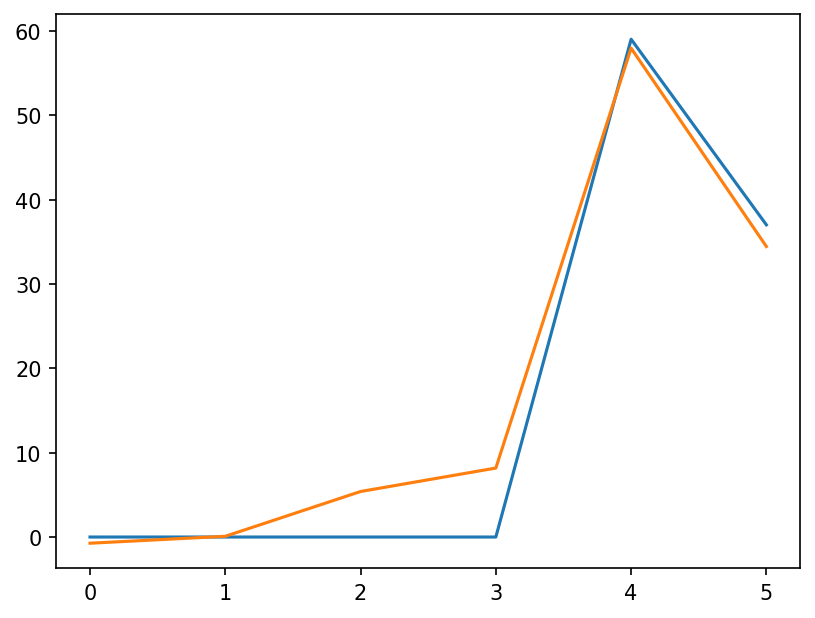

In [104]:
level=[0, 1, 2, 3, 4, 5]
plt.plot(level, w3_true)
plt.plot(level, w3_pred.detach().numpy())
plt.show

Design: Random PCL hitter to test.
Display: A 2x2 gridspec plot like the above with predicted vs real of years 3, 4, 5, 6 of the sample

I can use this code also to pilot code editing the playerID list to remove pitchers from the sample, which can later be imported back into the intl_league code above to greatly shorten API call cell on next execution.

In [105]:
pcl_team_ids = get_league_team_ids(teams, pcl_league_id)
print(pcl_team_ids)

Fetching list of teams in league 112:
----------------------------------------------
Round Rock Express
Sacramento River Cats
Oklahoma City Comets
Reno Aces
Albuquerque Isotopes
Las Vegas Aviators
Tacoma Rainiers
Salt Lake Bees
El Paso Chihuahuas
Sugar Land Space Cowboys
[102, 105, 238, 2310, 342, 400, 529, 561, 4904, 5434]


In [116]:
pcl_rosters = []
for team in pcl_team_ids:
    team_roster = get_team_roster_hitter_ids(team)
    pcl_rosters.extend(team_roster)


701648  Aaron Zavala {'code': '7', 'name': 'Outfielder', 'type': 'Outfielder', 'abbreviation': 'LF'}
666194  Cooper Johnson {'code': '2', 'name': 'Catcher', 'type': 'Catcher', 'abbreviation': 'C'}
660636  Diego Castillo {'code': '6', 'name': 'Shortstop', 'type': 'Infielder', 'abbreviation': 'SS'}
669413  Frainyer Chavez {'code': '4', 'name': 'Second Base', 'type': 'Infielder', 'abbreviation': '2B'}
822966  John Taylor {'code': '5', 'name': 'Third Base', 'type': 'Infielder', 'abbreviation': '3B'}
683149  Julian Brock {'code': '2', 'name': 'Catcher', 'type': 'Catcher', 'abbreviation': 'C'}
677601  Keyber Rodriguez {'code': '6', 'name': 'Shortstop', 'type': 'Infielder', 'abbreviation': 'SS'}
678636  Orlando Martinez {'code': 'O', 'name': 'Outfield', 'type': 'Outfielder', 'abbreviation': 'OF'}
806964  Sebastian Walcott {'code': '6', 'name': 'Shortstop', 'type': 'Infielder', 'abbreviation': 'SS'}
815152  Theo Hardy {'code': '6', 'name': 'Shortstop', 'type': 'Infielder', 'abbreviation': 'SS'

In [171]:
def test_random(model, id_list):
    choice = random.choice(id_list)
    player_dict = requests.get(f'https://statsapi.mlb.com/api/v1/people/{choice}',).json()
    print(f'Chosen player is: {player_dict['people'][0]['fullName']}')
    print('Fetching seasonal logs (approx. 15 seconds)...')
    vectors = get_all_season_vectors(choice, 2021, 2026)
    print('His actual seasonal vectors were:')
    print(f'2021: {vectors[0]}')
    print(f'2022: {vectors[1]}')
    print(f'2023: {vectors[2]}')
    print(f'2024: {vectors[3]}')
    print(f'2025: {vectors[4]}')
    print(f'2026: {vectors[5]}')
    w1 = torch.flatten(torch.tensor(vectors[0:2].copy()).float())
    w2 = torch.flatten(torch.tensor(vectors[1:3].copy()).float())
    w3 = torch.flatten(torch.tensor(vectors[2:4].copy()).float())
    w4 = torch.flatten(torch.tensor(vectors[3:5].copy()).float())
    print("Predicted seasons are:")
    pred_2023 = model(w1)
    pred_2024 = model(w2)
    pred_2025 = model(w3)
    pred_2026 = model(w4)
    print(f'2023: {pred_2023}')
    print(f'2024: {pred_2024}')
    print(f'2025: {pred_2025}')
    print(f'2026: {pred_2026}')
    # Graphing:
    level=[0, 1, 2, 3, 4, 5]
    fig = plt.figure(figsize=(10, 6), layout="constrained")
    gs = gridspec.GridSpec(nrows=3, ncols=2, figure=fig)

    ax2021= fig.add_subplot(gs[0, 0])
    ax2021.plot(level, vectors[0])
    ax2021.set_title(f'{player_dict['people'][0]['fullName']} 2021 (actual only)')

    ax2022= fig.add_subplot(gs[0, 1])
    ax2022.plot(level, vectors[1])
    ax2022.set_title(f'{player_dict['people'][0]['fullName']} 2022 (actual only)')

    ax2023 = fig.add_subplot(gs[1, 0])
    ax2023.plot(level, vectors[2], label = 'Actual')
    ax2023.plot(level, pred_2023.detach().numpy(), label = 'Predicted')
    ax2023.set_title(f'{player_dict['people'][0]['fullName']} 2023 (predicted & actual)')
    ax2023.legend()

    ax2024 = fig.add_subplot(gs[1, 1])
    ax2024.plot(level, vectors[3], label = 'Actual')
    ax2024.plot(level, pred_2024.detach().numpy(), label = 'Predicted')
    ax2024.set_title(f'{player_dict['people'][0]['fullName']} 2024 (predicted & actual)')
    ax2024.legend()

    ax2025 = fig.add_subplot(gs[2, 0])
    ax2025.plot(level, vectors[4], label = 'Actual')
    ax2025.plot(level, pred_2025.detach().numpy(), label = 'Predicted')
    ax2025.set_title(f'{player_dict['people'][0]['fullName']} 2025 (predicted & actual)')
    ax2025.legend()

    ax2026 = fig.add_subplot(gs[2, 1])
    ax2026.plot(level, vectors[3], label = 'Actual')
    ax2026.plot(level, pred_2026.detach().numpy(), label = 'Predicted')
    ax2026.set_title(f'{player_dict['people'][0]['fullName']} 2026 (predicted & actual)')
    ax2026.legend()

Chosen player is: Trevor Austin
Fetching seasonal logs (approx. 15 seconds)...
His actual seasonal vectors were:
2021: [0, 0, 0, 0, 0, 0]
2022: [0, 0, 0, 0, 0, 0]
2023: [0, 0, 0, 0, 0, 0]
2024: [0, 20, 0, 0, 0, 0]
2025: [0, 0, 25, 80, 0, 0]
2026: [0, 0, 0, 113, 12, 0]
Predicted seasons are:
2023: tensor([0.1641, 0.7950, 0.9797, 0.5412, 0.0715, 0.0483],
       grad_fn=<AddBackward0>)
2024: tensor([0.1641, 0.7950, 0.9797, 0.5412, 0.0715, 0.0483],
       grad_fn=<AddBackward0>)
2025: tensor([-0.0705,  4.2091, 18.2813,  3.5804,  0.2425,  0.4944],
       grad_fn=<AddBackward0>)
2026: tensor([ 1.3770, -0.1802,  2.3258, 52.0090, 20.0837,  4.8777],
       grad_fn=<AddBackward0>)


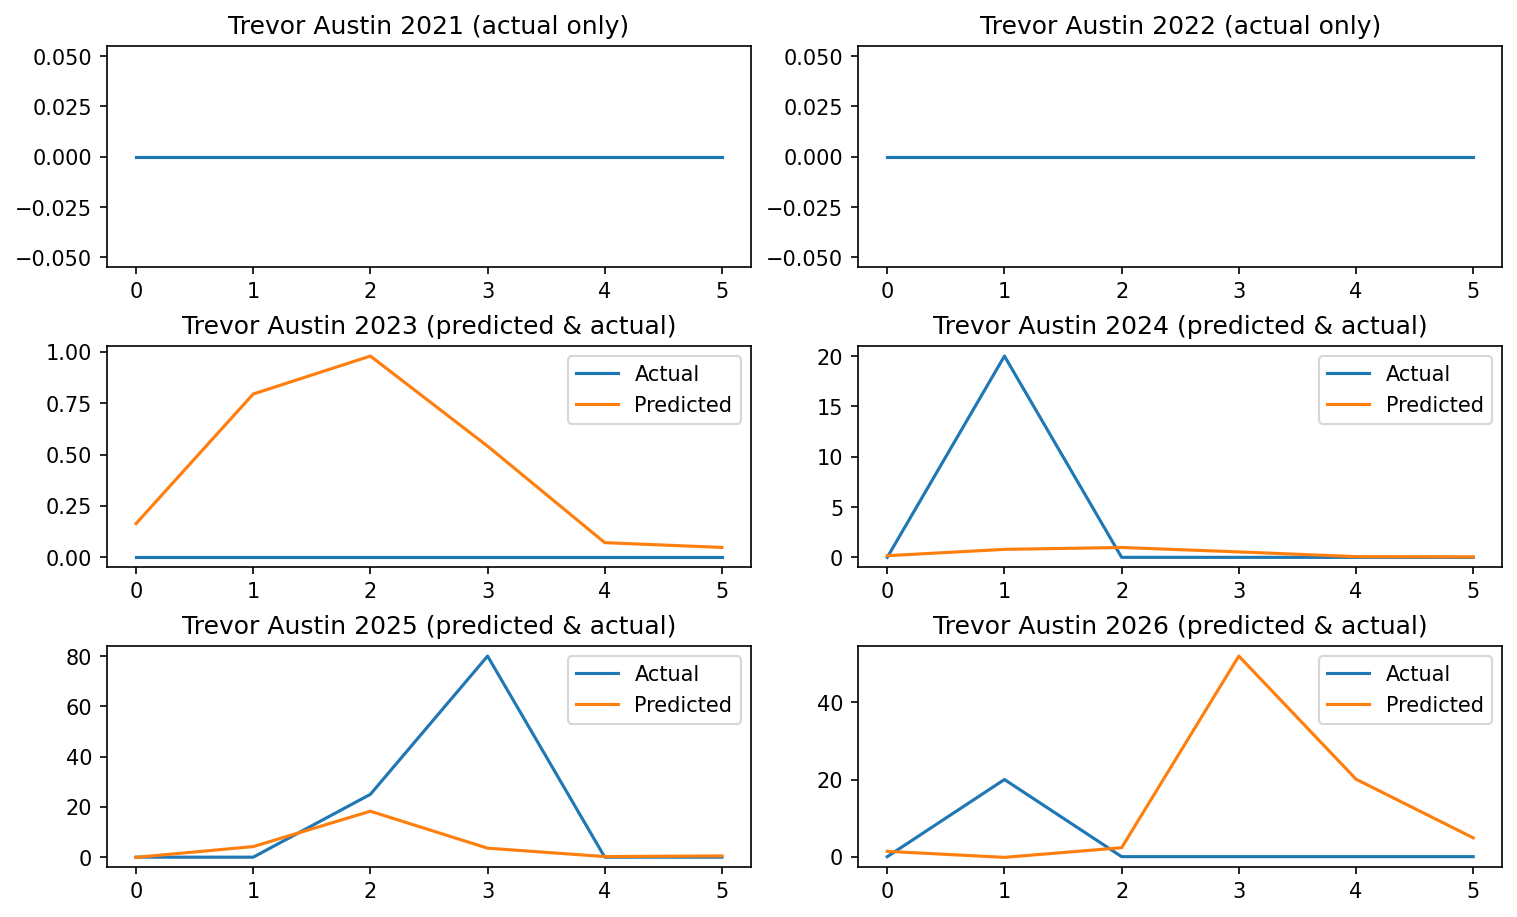

In [173]:
test_random(nbeats_pt, pcl_rosters)